In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
import joblib
import os

In [2]:
rfm_scaled = pd.read_csv(
    "../data/processed/customer_rfm_scaled.csv",
    index_col="CustomerID"
)

print(rfm_scaled.shape)
rfm_scaled.head()

(4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346,1.461993,-0.955214,3.707716
12347,-2.038734,1.074425,1.414903
12348,0.373104,0.386304,0.720024
12349,-0.623086,-0.955214,0.702287
12350,1.424558,-0.955214,-0.614514


In [3]:
isolation_model = IsolationForest(
    contamination=0.05,
    random_state=42,
    n_estimators=100
)

predictions = isolation_model.fit_predict(rfm_scaled)

print(np.unique(predictions, return_counts=True))

(array([-1,  1]), array([ 217, 4121]))


In [4]:
rfm_result = pd.read_csv(
    "../data/processed/customer_rfm.csv",
    index_col="CustomerID"
)

rfm_result["Anomaly"] = predictions

rfm_result["Customer_Status"] = rfm_result["Anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

rfm_result.head()

,Recency,Frequency,Monetary,Anomaly,Customer_Status
CustomerID,,,,,
12346,326,1,77183.60,-1,Anomaly
12347,2,7,4310.00,1,Normal
12348,75,4,1797.24,1,Normal
12349,19,1,1757.55,1,Normal
12350,310,1,334.40,1,Normal


In [5]:
print(
    rfm_result["Customer_Status"].value_counts()
)

Customer_Status
Normal     4121
Anomaly     217
Name: count, dtype: int64


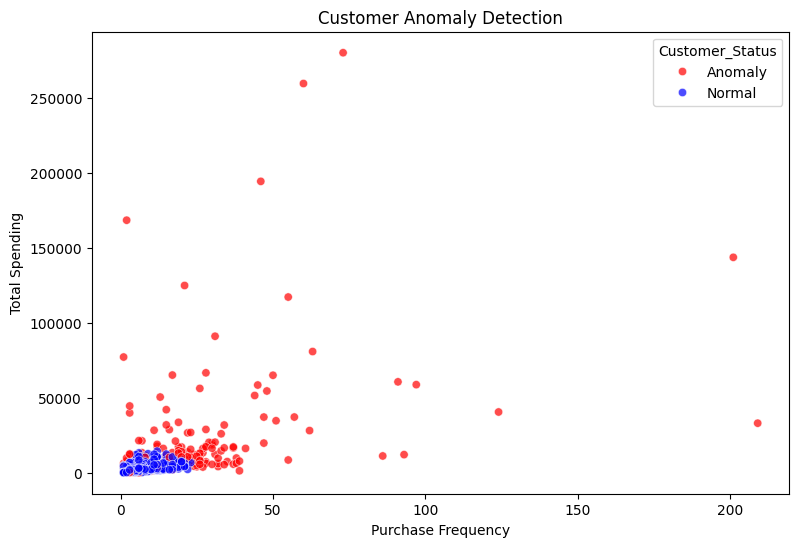

In [6]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm_result,
    x="Frequency",
    y="Monetary",
    hue="Customer_Status",
    palette={
        "Normal": "blue",
        "Anomaly": "red"
    },
    alpha=0.7
)

plt.title("Customer Anomaly Detection")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.show()

In [7]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

joblib.dump(
    isolation_model,
    "../models/isolation_forest.pkl"
)

rfm_result.to_csv(
    "../data/processed/customer_anomalies.csv"
)

print("Anomaly detection results saved successfully!")

Anomaly detection results saved successfully!
